In [ ]:
!pip -q install ultralytics pillow-heif

from google.colab import drive
drive.mount("/content/drive")

In [ ]:
from collections import Counter
from pathlib import Path

FOLDER_ID = "1oO7ep63brb7qTKpsiCEA-QBSvC155S08"
RAW = Path("/content/data_mentah")
BASE = Path("/content/drive/MyDrive/ekspresi_pengendara")
DATASET_DRIVE = BASE / "dataset"
HASIL = BASE / "hasil"

LOKAL = Path("/content/dataset")
BERSIH = Path("/content/bersih")
SISI = 384
IMGSZ = 320
SPLIT = (0.7, 0.15, 0.15) # train, val, test
SEED = 42
HASIL.mkdir(parents=True, exist_ok=True)

In [3]:
import threading
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

FOLDER = "application/vnd.google-apps.folder"


def daftar(service, folder_id):
    token = None
    while True:
        r = service.files().list(
            q=f"'{folder_id}' in parents and trashed=false",
            fields="nextPageToken, files(id, name, mimeType)", pageSize=1000, pageToken=token,
            supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
        yield from r["files"]
        token = r.get("nextPageToken")
        if not token:
            break


def kumpulkan(service, folder_id, tujuan, hasil):
    for it in daftar(service, folder_id):
        nama = it["name"].replace("/", "_")
        if it["mimeType"] == FOLDER:
            kumpulkan(service, it["id"], tujuan / nama, hasil)
        elif not it["mimeType"].startswith("application/vnd.google-apps"):
            hasil.append((it["id"], tujuan / nama))


_lokal = threading.local()


def unduh(args):
    fid, path = args
    if path.exists():
        return "lewati"
    try:
        if not hasattr(_lokal, "svc"):
            _lokal.svc = build("drive", "v3", cache_discovery=False)
        path.parent.mkdir(parents=True, exist_ok=True)
        req = _lokal.svc.files().get_media(fileId=fid, supportsAllDrives=True)
        with open(path, "wb") as fh:
            dl = MediaIoBaseDownload(fh, req, chunksize=8 * 1024 * 1024)
            selesai = False
            while not selesai:
                _, selesai = dl.next_chunk()
        return "ok"
    except Exception:
        path.unlink(missing_ok=True)
        return "gagal"


if (DATASET_DRIVE / "train").exists():
    print("Dataset olahan sudah ada di Drive, unduh data mentah dilewati.")
else:
    auth.authenticate_user()
    layanan = build("drive", "v3", cache_discovery=False)
    tugas = []
    kumpulkan(layanan, FOLDER_ID, RAW, tugas)
    print("File ditemukan di folder Drive:", len(tugas))
    with ThreadPoolExecutor(8) as ex:
        print(Counter(tqdm(ex.map(unduh, tugas), total=len(tugas))))   # ok / lewati / gagal
    print("Jika ada 'gagal', jalankan sel ini sekali lagi (yang sudah terunduh dilewati).")

File ditemukan di folder Drive: 354


  0%|          | 0/354 [00:00<?, ?it/s]

Counter({'ok': 354})
Jika ada 'gagal', jalankan sel ini sekali lagi (yang sudah terunduh dilewati).


In [4]:
if (DATASET_DRIVE / "train").exists() and not RAW.exists():
    print("Memakai dataset olahan yang sudah ada di Drive; cek data mentah dilewati.")
elif not RAW.exists():
    raise RuntimeError("Data mentah belum terunduh. Jalankan sel unduh di atas.")
else:
    total = 0
    for d in sorted(RAW.iterdir()):
        if d.is_dir():
            n = sum(1 for f in d.rglob("*") if f.is_file())
            total += n
            print(f"{d.name}: {n} file")
    print("Total:", total)

Dengan HP: 84 file
Fokus: 92 file
Mengantuk: 91 file
Merokok: 87 file
Total: 354


In [5]:
import hashlib, io, random, shutil
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from PIL import Image, ImageOps

try:
    import pillow_heif
    pillow_heif.register_heif_opener()
except ImportError:
    pass


def kecilkan(args):
    f, folder_kelas = args
    try:
        with Image.open(f) as im:
            im.draft("RGB", (SISI * 2, SISI * 2))
            im = ImageOps.exif_transpose(im).convert("RGB")
            lebar, tinggi = im.size
            skala = SISI / min(lebar, tinggi)
            if skala < 1:
                im = im.resize((round(lebar * skala), round(tinggi * skala)), Image.LANCZOS)
            buf = io.BytesIO()
            im.save(buf, "JPEG", quality=90)
        data = buf.getvalue()
        out = folder_kelas / (hashlib.md5(data).hexdigest() + ".jpg")
        if out.exists():
            return "duplikat"
        out.write_bytes(data)
        return "ok"
    except Exception:
        return "rusak"


if (DATASET_DRIVE / "train").exists():
    print("Dataset sudah ada di Drive, menyalin ke lokal...")
    shutil.copytree(DATASET_DRIVE, LOKAL, dirs_exist_ok=True)
else:
    shutil.rmtree(BERSIH, ignore_errors=True)
    tugas = []
    for d in sorted(RAW.iterdir()):
        if not d.is_dir():
            continue
        kelas = d.name.strip().lower().replace(" ", "_") # "Dengan HP" -> "dengan_hp"
        tujuan = BERSIH / kelas
        tujuan.mkdir(parents=True, exist_ok=True)
        tugas += [(f, tujuan) for f in d.rglob("*") if f.is_file()]
    print("Total file mentah:", len(tugas))

    with ThreadPoolExecutor(8) as ex:
        print(Counter(ex.map(kecilkan, tugas, chunksize=16)))

    random.seed(SEED)
    shutil.rmtree(LOKAL, ignore_errors=True)
    for d in sorted(BERSIH.iterdir()):
        files = sorted(d.glob("*.jpg"))
        random.shuffle(files)
        n = len(files)
        b1, b2 = int(n * SPLIT[0]), int(n * (SPLIT[0] + SPLIT[1]))
        for i, f in enumerate(files):
            sp = "train" if i < b1 else "val" if i < b2 else "test"
            (LOKAL / sp / d.name).mkdir(parents=True, exist_ok=True)
            shutil.copy(f, LOKAL / sp / d.name / f.name)
        print(f"{d.name}: {n} gambar bersih")

    print("Menyimpan dataset ke Drive...")
    shutil.copytree(LOKAL, DATASET_DRIVE, dirs_exist_ok=True)

for sp in ("train", "val", "test"):
    print(sp, {k.name: len(list(k.glob("*.jpg"))) for k in sorted((LOKAL / sp).iterdir())})

Total file mentah: 354
Counter({'ok': 350, 'duplikat': 4})
dengan_hp: 83 gambar bersih
fokus: 90 gambar bersih
mengantuk: 90 gambar bersih
merokok: 87 gambar bersih
Menyimpan dataset ke Drive...
train {'dengan_hp': 58, 'fokus': 62, 'mengantuk': 62, 'merokok': 60}
val {'dengan_hp': 12, 'fokus': 14, 'mengantuk': 14, 'merokok': 13}
test {'dengan_hp': 13, 'fokus': 14, 'mengantuk': 14, 'merokok': 14}


In [6]:
from ultralytics import YOLO

model = YOLO("yolov8s-cls.pt")
model.train(
    data=str(LOKAL), epochs=30, imgsz=IMGSZ, batch=32, patience=10,
    project="/content/runs", name="pengendara", exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hs

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x783fb4ba0550>
curves: []
curves_results: []
fitness: 0.9339622557163239
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.8679245114326477, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9339622557163239}
save_dir: PosixPath('/content/runs/pengendara')
speed: {'preprocess': 0.11034958490568587, 'inference': 0.7712223396223, 'loss': 0.00013224528303462134, 'postprocess': 0.0002644716983442502}
top1: 0.8679245114326477
top5: 1.0

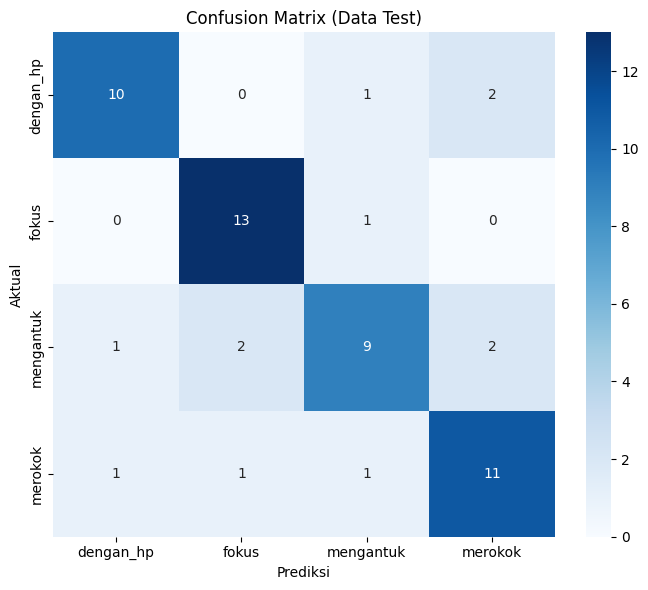

              precision    recall  f1-score   support

   dengan_hp     0.8333    0.7692    0.8000        13
       fokus     0.8125    0.9286    0.8667        14
   mengantuk     0.7500    0.6429    0.6923        14
     merokok     0.7333    0.7857    0.7586        14

    accuracy                         0.7818        55
   macro avg     0.7823    0.7816    0.7794        55
weighted avg     0.7814    0.7818    0.7790        55

Tersimpan di: /content/drive/MyDrive/ekspresi_pengendara/hasil ['confusion_matrix.png', 'laporan.json', 'best.pt']


In [7]:
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

best = YOLO(str(model.trainer.best))
names = [best.names[i] for i in range(len(best.names))]
idx = {n: i for i, n in enumerate(names)}

y_true, y_pred = [], []
for d in sorted((LOKAL / "test").iterdir()):
    for f in d.glob("*.jpg"):
        r = best(str(f), imgsz=IMGSZ, verbose=False)[0]
        y_true.append(idx[d.name])
        y_pred.append(int(r.probs.top1))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(names))))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.title("Confusion Matrix (Data Test)")
plt.tight_layout()
plt.savefig(HASIL / "confusion_matrix.png", dpi=150)
plt.show()

print(classification_report(y_true, y_pred, target_names=names, digits=4))
rep = classification_report(y_true, y_pred, target_names=names, output_dict=True)
laporan = {
    "kelas": names,
    "imgsz": IMGSZ,
    "akurasi": rep["accuracy"],
    "macro_f1": rep["macro avg"]["f1-score"],
    "jumlah_test": len(y_true),
    "matriks": cm.tolist(),
    "per_kelas": {n: rep[n] for n in names},
}
(HASIL / "laporan.json").write_text(json.dumps(laporan, indent=2, default=float), encoding="utf-8")
shutil.copy(model.trainer.best, HASIL / "best.pt")
print("Tersimpan di:", HASIL, [p.name for p in HASIL.iterdir()])